# Sommelier Algorítmico
**Proyecto Final - Arquitectura de Software**

Este cuaderno de Jupyter notebook documenta paso a paso la construcción de nuestro motor de Machine Learning que realiza la clasificación de los vinos y predice si un vino es de calidad Premium o Estándar basándose en los resultados de 11 pruebas fisicoquímicas hechas al vino.


## Carga y Exploración de Datos
Iniciamos cargando el dataset. En este caso, delimitamos el alcance al archivo de vino tinto de nombre (`winequality-red.csv`).

In [47]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "1"
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# 1. Cargamos el dataset local
data = pd.read_csv('winequality-red.csv', sep=';')

# Mostramos la información general y las primeras 5 filas para verificar los datos
print(f"Total de muestras de vino en el viñedo: {data.shape[0]}")
print(f"Total de variables (columnas): {data.shape[1]}")
data.head() # Uso de tabla para mostrar el dataset

Total de muestras de vino en el viñedo: 1599
Total de variables (columnas): 12


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Etiquetado de la variable de Calidad
El dataset originalmente evalúa la calidad de los vinos en una escala de 0 a 10. Sin embargo, para simplificar el problema y ajustarlo a los requerimientos del proyecto, se decidió transformarlo para realizar una tarea de clasificación binaria. Esta decisión también se alinea con la elección de utilizar el algoritmo de árbol de decisión, que permite trabajar con categorías discretas (0 y 1) y evita incorporar pesos asociados a múltiples niveles de calidad.

**Criterio de calidad del vino:**
* **Premium (1):** Calidad igual o superior a 7.
* **Estándar (0):** Calidad inferior a 7.

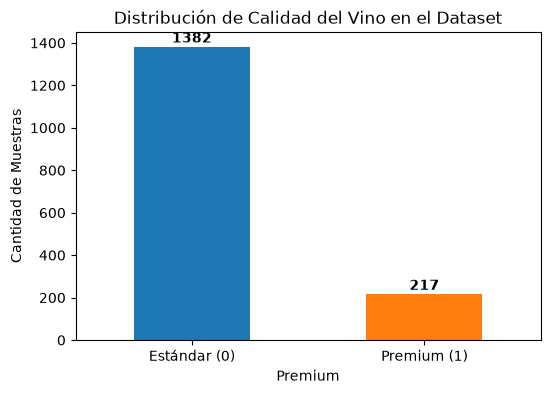

In [48]:
#  Aqui definimos si es Premium (1) la calidad debe ser mayor a  7 o Estándar si la calidad es menor a 7
data['Premium'] = data['quality'].apply(lambda x: 1 if x >= 7 else 0)

# Gráfica de barras del balance de clases
conteo_clases = data['Premium'].value_counts()
colores = ['#1f77b4', '#ff7f0e'] # Azul para estándar, Naranja para Premium

ax = conteo_clases.plot(kind='bar', color=colores, figsize=(6, 4))
plt.title('Distribución de Calidad del Vino en el Dataset', fontsize=12)
plt.xticks(ticks=[0, 1], labels=['Estándar (0)', 'Premium (1)'], rotation=0)
plt.ylabel('Cantidad de Muestras')

for i, v in enumerate(conteo_clases):
    ax.text(i, v + 20, str(v), ha='center', fontweight='bold')

plt.show()

## Separación de Datos
Como se documentó en la matriz de riesgos, existe el peligro de que el modelo genere resultados demasiado buenos con los datos de prueba si ve los datos de prueba durante su entrenamiento (*Data Leakage*) asi que decidimos se parar de form estricta el conjunto de datos para mitigar este riesgo asi:

* **80% de los datos** serán usados para entrenar el algoritmo.
* **20% de los datos** serán ocultados y usados para el test del modelo.
* Igualmenye eliminamos la columna `quality` del conjunto de datos original para que el sistema aprenda a deducirla química de forma correcta.

In [49]:
# Separar las 11 variables de entrada en X y la etiqueta de los datos, es importante eliminar la calidad de los datos  para que el modelo no tenga la respuesta al entrenarse.
X = data.drop(['quality', 'Premium'], axis=1)
y = data['Premium']

# Realizamos la separación de los datos 80% para que la máquina aprenda y 20% para el testeo
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("DIVISIÓN DE DATOS COMPLETADA")
print(f"Muestras para ENTRENAMIENTO (80%): {X_train.shape[0]} vinos.")
print(f"Muestras para PRUEBA FINAL  (20%): {X_test.shape[0]} vinos.")

# Se imprime un ejemplo de los datos fisicoquimicos que se infgresaran al modelo, verificamos que no haya columna de calidad.
print("\nEjemplo de los 11 parámetros químicos listos para el algoritmo:")
X_train.head(2)

DIVISIÓN DE DATOS COMPLETADA
Muestras para ENTRENAMIENTO (80%): 1279 vinos.
Muestras para PRUEBA FINAL  (20%): 320 vinos.

Ejemplo de los 11 parámetros químicos listos para el algoritmo:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
56,10.2,0.42,0.57,3.4,0.070,4.0,10.0,0.99710,3.04,0.63,9.6
1017,8.0,0.18,0.37,0.9,0.049,36.0,109.0,0.99007,2.89,0.44,12.7


## Entrenamiento
Procedemos a entrenar algoritmo de **Árbol de Decisión**. pero es imprtante aplicar dos configuraciones:
1. `max_depth=5`: que vita que el modelo memorice los datos en lugar de aprender.
2. `class_weight='balanced'`: que obliga a la máquina a prestar más atención a los vinos Premium, mitigando el impacto del desbalance que vimos en la gráfica del Paso 2.

Finalmente,  cumplimos con el requerimiento de **"Modelo Reemplazable"** exportando el algoritmo entrenado a un archivo físico `.pkl`.

In [50]:
# Entrenamiento del modelo a traved de la técnica de Árbol de Decisión
modelo = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=6,
    min_samples_split=10,
    class_weight={0: 1, 1: 2.5},
    random_state=42 # Para asegurar la reproducibilidad
)
modelo.fit(X_train, y_train)

# Guardamos el modelo para ser usado luego por la API
with open('wine_quality_model.pkl', 'wb') as f:
    pickle.dump(modelo, f)

# imprimimos un mensaje que nos muestre el resultado para continuar 
print("Entrenamiento completado")
print("Archivo 'wine_quality_model.pkl' generado en el directorio local.")

Entrenamiento completado
Archivo 'wine_quality_model.pkl' generado en el directorio local.


## Evaluación del modelo y Matriz de Confusión
Sometemos al modelo a evaluación del entrenamiento con el 20% de los datos que habiamos separado anteriormente. Ahora, es importante tener en cuenta que nuestro criterio de éxito exige un **Accuracy (Exactitud) mínimo del 80%** y una capacidad sólida para detectar la clase Premium (Recall). Analizaremos el "trade-off" de nuestra decisión de balancear las clases mediante la Precisión, el F1-Score y la Matriz de Confusión.

RESULTADOS DEL TESTEO FINAL DEL MODELO
Accuracy (Exactitud):   88.44 %
Precision (Precisión):  55.56 %
Recall (Exhaustividad): 69.77 %
F1-Score:               61.86 %
------------------------------------------------------------


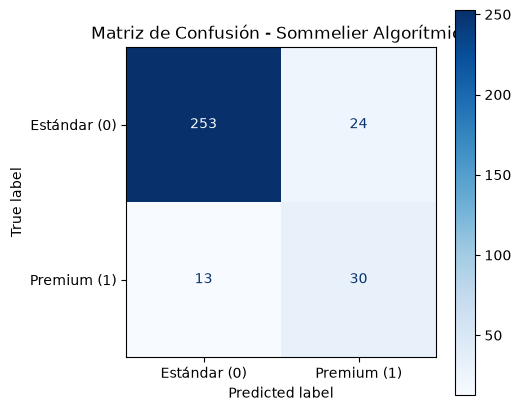

In [51]:
# Empezamos a ejecutar predicciones a partir del 20% de los datos que no se usaron en el entrenamiento:
y_pred = modelo.predict(X_test)

print("RESULTADOS DEL TESTEO FINAL DEL MODELO")
print(f"Accuracy (Exactitud):   {accuracy_score(y_test, y_pred)*100:.2f} %")
print(f"Precision (Precisión):  {precision_score(y_test, y_pred)*100:.2f} %")
print(f"Recall (Exhaustividad): {recall_score(y_test, y_pred)*100:.2f} %")
print(f"F1-Score:               {f1_score(y_test, y_pred)*100:.2f} %")
print("-" * 60)

# Creamos una Matriz de Confusión para el análisis de los resultados:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Estándar (0)', 'Premium (1)'])
fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Matriz de Confusión - Sommelier Algorítmico")
plt.show()

## Simulador de la API
Para demostrar la viabilidad de la arquitectura propuesta de la capa de la aplicación, vamos a simular el comportamiento exacto que tendrá nuestra API. 

Para esta prueba, el sistema no usará datos de entrenamiento. En su lugar:
1. Cargará el modelo entrenado desde el archivo `.pkl`.
2. Recibirá un archivo JSON con 11 parámetros químicos de un vino de prueba.
3. Emitirá el concepto de calidad en tiempo real.

In [ ]:
# Una vez guardados nuestro modelo podemos hacer pruebas de la API

# Primero cargamos el modelo desde el archivo pkl que generamos asi como lo hará la API
with open('wine_quality_model.pkl', 'rb') as f:
    modelo_cargado = pickle.load(f)

# Simulamos los datos ingresados por un enólogo en la página web con parámetros que corresponden a un vino de alta calidadinicialmente
vino_nuevo = {
    "fixed acidity": 7.4,
    "volatile acidity": 0.36,
    "citric acid": 0.30,
    "residual sugar": 1.8,
    "chlorides": 0.074,
    "free sulfur dioxide": 17.0,
    "total sulfur dioxide": 24.0,
    "density": 0.99419,
    "pH": 3.24,
    "sulphates": 0.70,
    "alcohol": 11.4
}

print("Variables quimicas recibidas, analizando una nueva muestra química...")

# Convertimos el diccionario a un DataFrame de 1 fila que es el formato requerido por Scikit-Learn
df_vino_nuevo = pd.DataFrame([vino_nuevo])

# Y finalmente obtenemos el veredicto que nos genera el modelo
prediccion = modelo_cargado.predict(df_vino_nuevo)

print("\nVEREDICTO DEL SOMMELIER ALGORÍTMICO")
if prediccion[0] == 1:
    print("VINO premium, se prevee calidad mayor a 7")
    print("Recomendación: Proceder con embotellado de reserva especial.")
else:
    print("VINO estándar, se prevee Calidad menor a 7")
    print("Recomendación: Destinar a línea de producción comercial básica.")

Variables quimicas recibidas, analizando una nueva muestra química...

VEREDICTO DEL SOMMELIER ALGORÍTMICO
VINO premium, se prevee calidad mayor 7
Recomendación: Proceder con embotellado de reserva especial.
